In [5]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


df = pd.read_csv("/home/asus/Machine-Learning/ml-zoomcamp-2k26/module_3_classification/datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

df.dtypes

df.columns = df.columns.str.lower().str.replace(' ', '_')
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(" ", "_")
    

df.head().T

# one can see in the above dataframe that totalcharges row has float values displayed but they are mentioned as string

df.totalcharges = pd.to_numeric(df.totalcharges, errors="coerce")
df.totalcharges = df.totalcharges.fillna(0)

df.dtypes

df.churn.head()

df['churn'] = (df.churn == 'yes').astype(int)
df.churn.head()

# data preperation is done...

# setting up validation framework ... by Performing the train/validation/test split with Scikit-Learn

from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

# random_state is to generate random numbers...

len(df_train), len(df_val), len(df_test)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop = True)
df_test = df_val.reset_index(drop = True)

y_train = df_train['churn'].values
y_val = df_val['churn'].values
y_test = df_test['churn'].values

#these are the required output used for verification and accuracy checking

del(df_train['churn'])
del(df_val['churn'])
del(df_test['churn'])

# EDA (Exploratory Data Analysis)
"""Check missing values
Look at the target variable (churn)
Look at numerical and categorical variables"""

df_full_train.reset_index(drop = True)

df_full_train.churn.value_counts(normalize = True)

categorical = list(df.dtypes[(df.dtypes == 'str') & (df.columns != 'customerid')].index)
categorical

['gender',
 'partner',
 'dependents',
 'phoneservice',
 'multiplelines',
 'internetservice',
 'onlinesecurity',
 'onlinebackup',
 'deviceprotection',
 'techsupport',
 'streamingtv',
 'streamingmovies',
 'contract',
 'paperlessbilling',
 'paymentmethod']

In [6]:
df.T

,0,1,2,3,4,5,6,7,8,9,...,7033,7034,7035,7036,7037,7038,7039,7040,7041,7042
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu,9305-cdskc,1452-kiovk,6713-okomc,7892-pookp,6388-tabgu,...,9767-fflem,0639-tsiqw,8456-qdavc,7750-eyxwz,2569-wgero,6840-resvb,2234-xaduh,4801-jzazl,8361-ltmkd,3186-ajiek
gender,female,male,male,male,female,female,male,female,female,male,...,male,female,male,female,female,male,female,female,male,male
seniorcitizen,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
partner,yes,no,no,no,no,no,no,no,yes,no,...,no,no,no,no,no,yes,yes,yes,yes,no
dependents,no,no,no,no,no,no,yes,no,no,yes,...,no,no,no,no,no,yes,yes,yes,no,no
tenure,1,34,2,45,2,8,22,10,28,62,...,38,67,19,12,72,24,72,11,4,66
phoneservice,no,yes,yes,no,yes,yes,yes,no,yes,yes,...,yes,yes,yes,no,yes,yes,yes,no,yes,yes
multiplelines,no_phone_service,no,no,no_phone_service,no,yes,yes,no_phone_service,yes,no,...,no,yes,no,no_phone_service,no,yes,yes,no_phone_service,yes,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic,fiber_optic,fiber_optic,dsl,fiber_optic,dsl,...,fiber_optic,fiber_optic,fiber_optic,dsl,no,dsl,fiber_optic,dsl,fiber_optic,fiber_optic
onlinesecurity,no,yes,yes,yes,no,no,no,yes,no,yes,...,no,yes,no,no,no_internet_service,yes,no,yes,no,yes


In [7]:
numerical = list(df.dtypes[(((df.dtypes == 'int64') | (df.dtypes == 'float64')) & (df.columns != 'churn'))].index)
numerical

['seniorcitizen', 'tenure', 'monthlycharges', 'totalcharges']

In [16]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

dv = DictVectorizer()
train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(max_iter = 5000)
model.fit(X_train, y_train)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred > 0.5)
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [17]:
len(y_val == 1)

1409

In [18]:
(y_val == churn_decision).sum().item()

1132

In [19]:
1132/1409

0.8034066713981547

In [20]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)

0.8034066713981547

In [21]:
# you can see that the accuracy come from the my manual way above and by the readymade function both are same around 80%
# Now lets focus on the thresolds and their selection

In [22]:
thresholds = np.linspace(0, 1, 21)
scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)

    print("%.2f %.3f" %(t, score))
    scores.append(score)

0.00 0.274
0.05 0.512
0.10 0.607
0.15 0.661
0.20 0.703
0.25 0.735
0.30 0.759
0.35 0.767
0.40 0.782
0.45 0.791
0.50 0.803
0.55 0.802
0.60 0.796
0.65 0.789
0.70 0.766
0.75 0.742
0.80 0.730
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


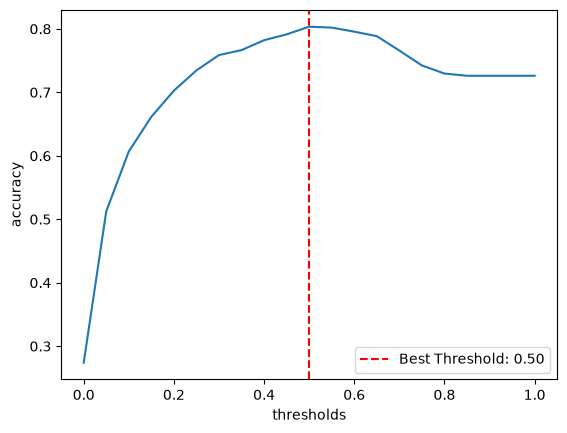

In [23]:
plt.plot(thresholds, scores)

max_score = max(scores)
best_threshold = thresholds[scores.index(max_score)]

plt.axvline(
    x=best_threshold,
    color="red",
    linestyle="--",
    label=f"Best Threshold: {best_threshold:.2f}",
)

plt.xlabel("thresholds")
plt.ylabel("accuracy")
plt.legend()

In [24]:
from collections import Counter

print(Counter(y_pred >= 1.0))
print(Counter(y_pred > 0.5))

# 1094 → Model predicts NOT CHURN (0)
# 315 → Model predicts CHURN (1)

Counter({np.False_: 1409})
Counter({np.False_: 1094, np.True_: 315})


In [25]:
# Counts how many times both y_val and churn_decision are 1 (True Positives)
((y_val == 1)).sum()

np.int64(386)

In [26]:
"""
1094 ko bola: Churn nahi karenge
315 ko bola: Churn karenge
1132 predictions sahi nikli
277 predictions galat nikli.
"""

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predicted_positive = (y_pred >= t)
predicted_negative = (y_pred < t)

tp = (actual_positive & predicted_positive).sum()
tn = (actual_negative & predicted_negative).sum()

fp = (actual_negative & predicted_positive).sum()
fn = (actual_positive & predicted_negative).sum()

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

confusion_matrix

array([[920, 103],
       [174, 212]])

In [27]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

In [28]:
"""
Precision: Jinhe churner bola, unmein kitne sach mein churn karenge?

Recall: Jo sach mein churn karenge, unmein se kitno ko pakda?
"""

p = tp / (tp + fp) # precision

r = tp / (tp + fn) # recall

print(p)
print(r)

0.6730158730158731
0.5492227979274611


In [29]:
"""TPR — True Positive Rate (Recall)"""
tpr = tp / (tp + fn)

"""FPR - Jo actual mai negative thhe but unko postitive bolke ke muft ka offer baat dala"""
fpr = fp / (fp + tn)

print("TPR:", tpr)
print("FPR:", fpr)

# ye percentage total numbers ka percentage nhi hai, jo category mai hamne bande dhunde thhe unme se kitne vakai valid thhe, vo percentage hai

TPR: 0.5492227979274611
FPR: 0.10068426197458455


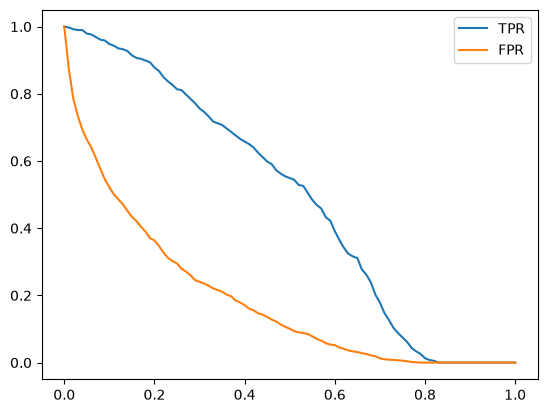

In [30]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predicted_positive = (y_pred >= t)
    predicted_negative = (y_pred < t)
    
    tp = (actual_positive & predicted_positive).sum()
    tn = (actual_negative & predicted_negative).sum()
    
    fp = (actual_negative & predicted_positive).sum()
    fn = (actual_positive & predicted_negative).sum()

    scores.append((t, tp, fp, tn, fn))

columns = ['thresholds', 'tp', 'fp', 'tn', 'fn']
df_scores = pd.DataFrame(scores, columns=columns)


df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

plt.plot(df_scores.thresholds, df_scores['tpr'], label = 'TPR')
plt.plot(df_scores.thresholds, df_scores['fpr'], label = 'FPR')
plt.legend()

In [31]:
# We got this result by our model... lets compare it with a base line and that may be a random model
np.random.seed(1)

y_rand = np.random.uniform(0, 1, len(y_val))

In [32]:
((y_rand > 0.5) == y_val).mean()

np.float64(0.5017743080198722)

In [33]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []
    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predicted_positive = (y_pred >= t)
        predicted_negative = (y_pred < t)

        tp = (actual_positive & predicted_positive).sum()
        tn = (actual_negative & predicted_negative).sum()
        
        fp = (actual_negative & predicted_positive).sum()
        fn = (actual_positive & predicted_negative).sum()

        scores.append((t, tp, fp, tn, fn))

    columns = ['thresholds', 'tp', 'fp', 'tn', 'fn']
    df_scores = pd.DataFrame(scores, columns=columns)
    
    
    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores
        

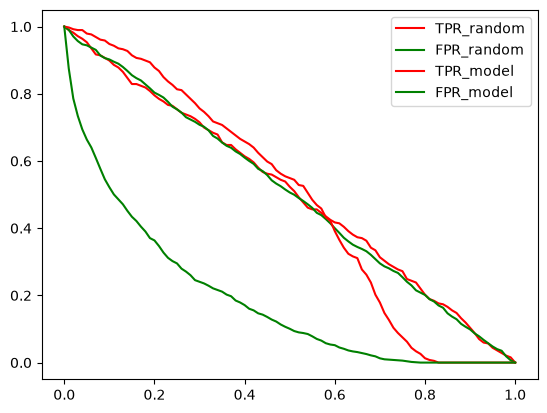

In [34]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

plt.plot(df_rand.thresholds, df_rand['tpr'], label='TPR_random', color = 'red')
plt.plot(df_rand.thresholds, df_rand['fpr'], label='FPR_random', color = 'green')
plt.plot(df_scores.thresholds, df_scores['tpr'], label = 'TPR_model', color = 'red')
plt.plot(df_scores.thresholds, df_scores['fpr'], label = 'FPR_model', color = 'green')
plt.legend()

In [35]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

(num_neg, num_pos)

(np.int64(1023), np.int64(386))

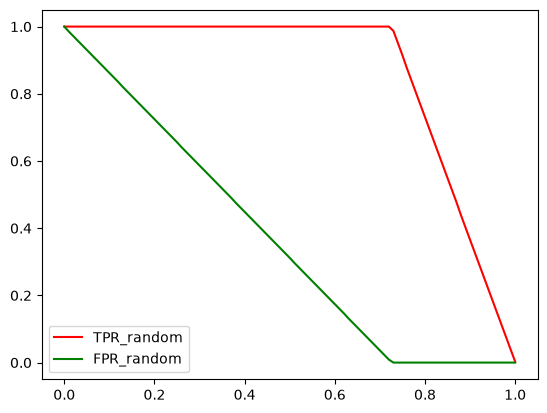

In [36]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))

df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

plt.plot(df_ideal.thresholds, df_ideal['tpr'], label='TPR_random', color = 'red')
plt.plot(df_ideal.thresholds, df_ideal['fpr'], label='FPR_random', color = 'green')
plt.legend()

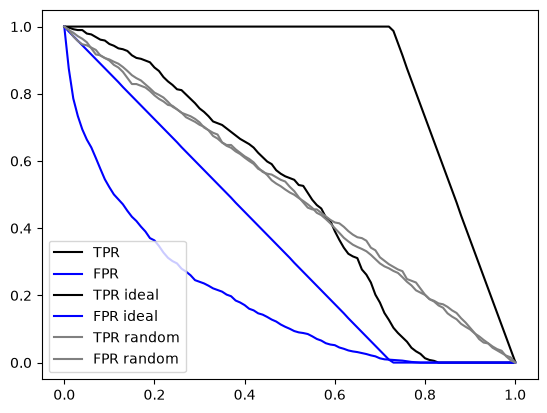

In [37]:
plt.plot(df_scores.thresholds, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.thresholds, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.thresholds, df_ideal['tpr'], label='TPR ideal', color='black')
plt.plot(df_ideal.thresholds, df_ideal['fpr'], label='FPR ideal', color='blue')

plt.plot(df_rand.thresholds, df_rand['tpr'], label='TPR random', color='grey')
plt.plot(df_rand.thresholds, df_rand['fpr'], label='FPR random', color='grey')

plt.legend()

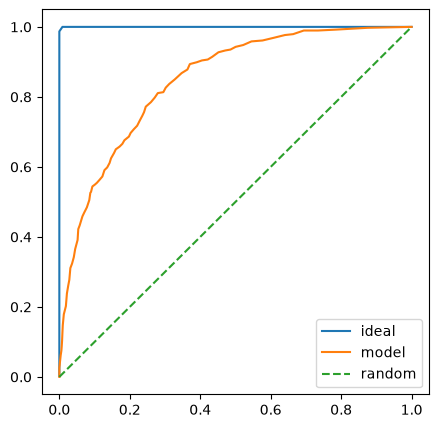

In [38]:
plt.figure(figsize=(5,5))

plt.plot(df_ideal.fpr, df_ideal.tpr, label = 'ideal')
plt.plot(df_scores.fpr, df_scores.tpr, label = 'model')
plt.plot([0, 1], [0, 1], label='random', linestyle='--')
plt.legend()

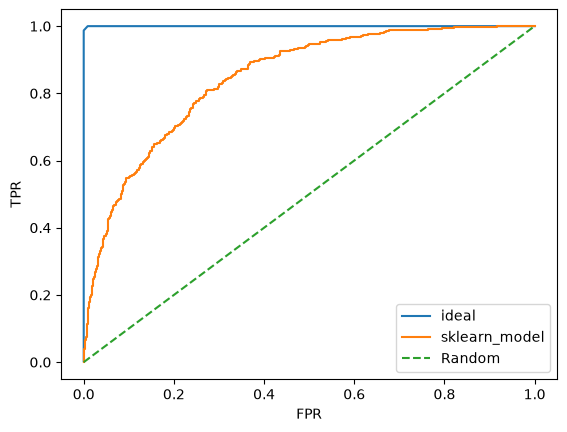

In [39]:
# same hustle that u did above can be done by sckit-learn

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

plt.plot(df_ideal.fpr, df_ideal.tpr, label = 'ideal')
plt.plot(fpr, tpr, label = 'sklearn_model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

In [44]:
# So from their, one can conclude that to reach the ideality the AUC must be as high as possible upto the ideal one

from sklearn.metrics import auc

auc(fpr, tpr)
# remember don't do auc(tpr, fpr)

0.8463272200527758

In [45]:
# from our model
auc(df_scores.fpr, df_scores.tpr)

0.846025861152052

In [47]:
# almost similar result
# for ideal case

auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [54]:
"""
ROC AUC Score (Receiver Operating Characteristic – Area Under the Curve) is a classification evaluation metric that measures a model's ability to distinguish between positive and negative classes across all classification thresholds.
It represents the area under the ROC curve, which plots True Positive Rate (TPR) against False Positive Rate (FPR).
- AUC = 1: Perfect discrimination.
- AUC = 0.5: Random guessing level.
- AUC < 0.5: Worse-than-random ranking.
Intuition: AUC = 0.85 means there is an 85% probability that a randomly selected positive example receives a higher predicted score than a randomly selected negative example (with ties counted as half).
"""

"""
This means that take 85% as our answer then it means that 85% times, when I choose a random guy from the group of the ones who are gonna churn have threshold_value/probability of churning higher than the one not choosed from the group who is not gonna churn... 

See the example below
"""


pos = y_pred[y_val == 1] # this includes the list of all the probability values for which ""y_val == 1""
neg = y_pred[y_val == 0]

print(pos[:10],"\n\n\n",  neg[:10])

[0.56363596 0.59494393 0.46557288 0.73694888 0.08204313 0.69507429
 0.24832958 0.68801499 0.21810495 0.66271045] 


 [0.00670939 0.20445793 0.21752441 0.21834481 0.23072052 0.03424355
 0.00192936 0.03112816 0.47928442 0.09123281]


In [59]:
# there may be cases when values in neg list is higher than the pos list like last second in the above output "0.21810495 and 0.47928442".
# and how less those numbers are determines how better your model predicts and hence higher the AUC or ROC_AUC_SCORE

import random

random.seed(1)

n = 10000
success = 0

for i in range(n):
    pos_idx = random.randint(1, len(pos)-1)
    neg_idx = random.randint(1, len(neg)-1)

    if(pos[pos_idx] > neg[neg_idx]):
        success += 1;

print(success/n) # u can see that this is almost equal to the AUC value above
# If we randomly pick one actual churner and one actual non-churner, there is approximately an 84% chance that our model assigns a higher churn probability to the actual churner
# one thing to remember the upper_value of the domain is exclusive if we use random using numpy

0.8467


In [66]:
# tqdm is a Python library that displays a progress bar for loops, showing how much work is completed and approximately how much time remains.
from tqdm.auto import tqdm
from sklearn.model_selection import KFold

In [81]:
def train(df_train, y_train, C):
    df_dict = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer()
    X_train = dv.fit_transform(df_dict)

    model = LogisticRegression(C = C, max_iter = 5000)
    model.fit(X_train, y_train)
    return dv, model

def predict(df_val, dv, model):
    df_dict = df_val[categorical + numerical].to_dict(orient='records')

    X_val = dv.transform(df_dict)
    y_pred = model.predict_proba(X_val)[:, 1]

    return y_pred

In [86]:
from sklearn.metrics import roc_auc_score

n_splits = 5
scores = []

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits = n_splits, shuffle = True, random_state = 1)


    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
        
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print(f"C={C} {np.mean(scores): 0.5f} +- {np.std(scores): 0.5f}")

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001  0.82507 +-  0.00928
C=0.01  0.83251 +-  0.01151
C=0.1  0.83562 +-  0.01118
C=0.5  0.83719 +-  0.01063
C=1  0.83813 +-  0.01016
C=5  0.83874 +-  0.00978
C=10  0.83918 +-  0.00948


In [87]:
scores

[0.8256234741857745,
 0.8335009435836312,
 0.8102388119606663,
 0.8201880955426233,
 0.8358186125317688,
 0.8429834132709533,
 0.8464959111375976,
 0.8293076459963877,
 0.8311596693739208,
 0.8498203696150106,
 0.8445494579679883,
 0.8458834094821879,
 0.8329399959863537,
 0.8340414561616678,
 0.8517382573499419,
 0.8444945090312502,
 0.8451508906105152,
 0.8335380292996186,
 0.8346689742277931,
 0.8517264911675191,
 0.8444277853223541,
 0.8449232717520859,
 0.8336223158739716,
 0.8347409189742279,
 0.8516715823162122,
 0.8440823920057147,
 0.8448901635544961,
 0.8333935380292997,
 0.8347848852081602,
 0.8517970882620564,
 0.8439724941322386,
 0.8447535922394385,
 0.8336343568131649,
 0.8347529097653004,
 0.8520481001537448]